# Устойчивость CNN к сдвигам изображений

Проверим на MNIST три варианта: базовую CNN, ту же сеть с аугментацией
и более глубокую CNN с AveragePooling.

У всех моделей одинаковые Adam, Dropout, batch size и число эпох.
Каждый вариант обучаем с тремя seed. Для обучения используем train,
для кривых обучения — validation. Test проверяем после обучения всех моделей.


In [6]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (7, 7)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

seeds = [111, 222, 333]
epochs = 10
batch_size = 128
learning_rate = 0.001
dropout = 0.2

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


Device: cuda


**ДАННЫЕ**

ToTensor переводит пиксели в float32 от 0 до 1, размер одного изображения — (1, 28, 28).
Из исходного train выделяем 6000 изображений для validation.
В аугментированном train используются те же индексы, но изображения случайно
сдвигаются по двум осям в пределах 6 пикселей. Вращения нет, пустые области чёрные.
Датасет сохраняет свой размер, поэтому число шагов обучения одинаково.


In [7]:
train_data = datasets.MNIST('data', train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST('data', train=False, download=True, transform=transforms.ToTensor())

train_set, val_set = random_split(
    train_data, [54000, 6000], generator=torch.Generator().manual_seed(67))
# случайное аффинное преобразование, без поворотов
augmented_data = datasets.MNIST('data', train=True, download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.RandomAffine(degrees=0, translate=(6 / 28, 6 / 28), fill=0)
    ]))
train_aug_set = Subset(augmented_data, train_set.indices)

val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print('Train:', len(train_set))
print('Validation:', len(val_set))
print('Test:', len(test_data))


Train: 54000
Validation: 6000
Test: 10000


**АРХИТЕКТУРЫ**

В базовой сети — три свёртки и два MaxPooling. В глубокой — пять свёрток
и AveragePooling перед линейными слоями. Последний слой выдаёт 10 логитов.
Для них используем CrossEntropyLoss.


In [8]:
def make_model(deep=False):
    if deep:
        return nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.AvgPool2d(7),
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    return nn.Sequential(
        nn.Conv2d(1, 64, 3, padding=1),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 64, 3),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 64, 3),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 128),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(128, 10)
    )


In [9]:
experiments = [
    ('Базовая CNN', train_set, False),
    ('Базовая CNN + аугментация', train_aug_set, False),
    ('Глубокая CNN', train_set, True)
]

print(make_model())
print(make_model(deep=True))


Sequential(
  (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (5): ReLU()
  (6): Dropout(p=0.2, inplace=False)
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (9): ReLU()
  (10): Dropout(p=0.2, inplace=False)
  (11): Flatten(start_dim=1, end_dim=-1)
  (12): Linear(in_features=1024, out_features=128, bias=True)
  (13): ReLU()
  (14): Dropout(p=0.2, inplace=False)
  (15): Linear(in_features=128, out_features=10, bias=True)
)
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): 

**ОБУЧЕНИЕ**

На каждом запуске создаём новую модель и оптимизатор. В model.train() Dropout
работает, в model.eval() отключается. При проверке градиенты не вычисляем.
Loss и accuracy считаем по всем изображениям, включая последний неполный batch.


In [10]:
criterion = nn.CrossEntropyLoss()
runs = []

for name, dataset, deep in experiments:
    for seed in seeds:
        print(f'\n{name}, seed={seed}')
        torch.manual_seed(seed)
        model = make_model(deep).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
        train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,generator=torch.Generator().manual_seed(seed))

        train_losses, val_losses = [], []
        train_accuracies, val_accuracies = [], []

        for epoch in range(epochs):
            model.train()
            train_loss = 0
            train_correct = 0

            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)

                optimizer.zero_grad()
                logits = model(images)
                loss = criterion(logits, labels)
                loss.backward()
                optimizer.step()

                train_loss += loss.item() * images.size(0)
                train_correct += (logits.argmax(dim=1) == labels).sum().item()

            train_losses.append(train_loss / len(dataset))
            train_accuracies.append(train_correct / len(dataset))

            model.eval()
            val_loss = 0
            val_correct = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images, labels = images.to(device), labels.to(device)
                    logits = model(images)
                    val_loss += criterion(logits, labels).item() * images.size(0)
                    val_correct += (logits.argmax(dim=1) == labels).sum().item()

            val_losses.append(val_loss / len(val_set))
            val_accuracies.append(val_correct / len(val_set))

            print(f'Epoch {epoch + 1}/{epochs} | '
                  f'loss: {train_losses[-1]:.4f}, accuracy: {train_accuracies[-1]:.4f} | '
                  f'val loss: {val_losses[-1]:.4f}, val accuracy: {val_accuracies[-1]:.4f}')

        # оставляем модели для финальной проверки, освобождаем память GPU
        runs.append({
            'name': name, 'seed': seed, 'model': model.cpu(),
            'train_loss': train_losses, 'val_loss': val_losses,
            'train_accuracy': train_accuracies, 'val_accuracy': val_accuracies
        })



Базовая CNN, seed=111
Epoch 1/10 | loss: 0.2638, accuracy: 0.9176 | val loss: 0.0813, val accuracy: 0.9788
Epoch 2/10 | loss: 0.0711, accuracy: 0.9780 | val loss: 0.0515, val accuracy: 0.9862
Epoch 3/10 | loss: 0.0504, accuracy: 0.9846 | val loss: 0.0415, val accuracy: 0.9887
Epoch 4/10 | loss: 0.0416, accuracy: 0.9868 | val loss: 0.0388, val accuracy: 0.9883
Epoch 5/10 | loss: 0.0345, accuracy: 0.9888 | val loss: 0.0397, val accuracy: 0.9878
Epoch 6/10 | loss: 0.0307, accuracy: 0.9901 | val loss: 0.0317, val accuracy: 0.9902
Epoch 7/10 | loss: 0.0289, accuracy: 0.9908 | val loss: 0.0323, val accuracy: 0.9908
Epoch 8/10 | loss: 0.0251, accuracy: 0.9920 | val loss: 0.0279, val accuracy: 0.9910
Epoch 9/10 | loss: 0.0221, accuracy: 0.9931 | val loss: 0.0266, val accuracy: 0.9918
Epoch 10/10 | loss: 0.0210, accuracy: 0.9932 | val loss: 0.0267, val accuracy: 0.9923

Базовая CNN, seed=222
Epoch 1/10 | loss: 0.2554, accuracy: 0.9193 | val loss: 0.0835, val accuracy: 0.9792
Epoch 2/10 | loss:

**ГРАФИКИ ОБУЧЕНИЯ**

Средние loss и accuracy по трём seed.


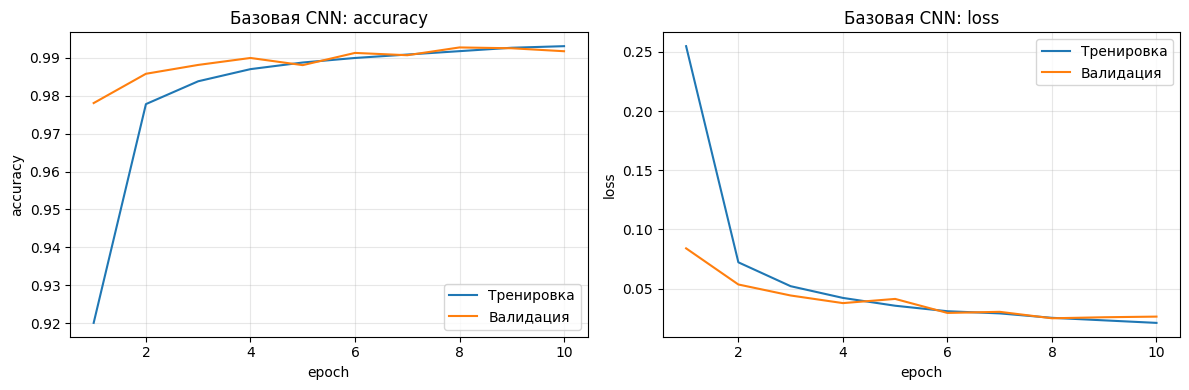

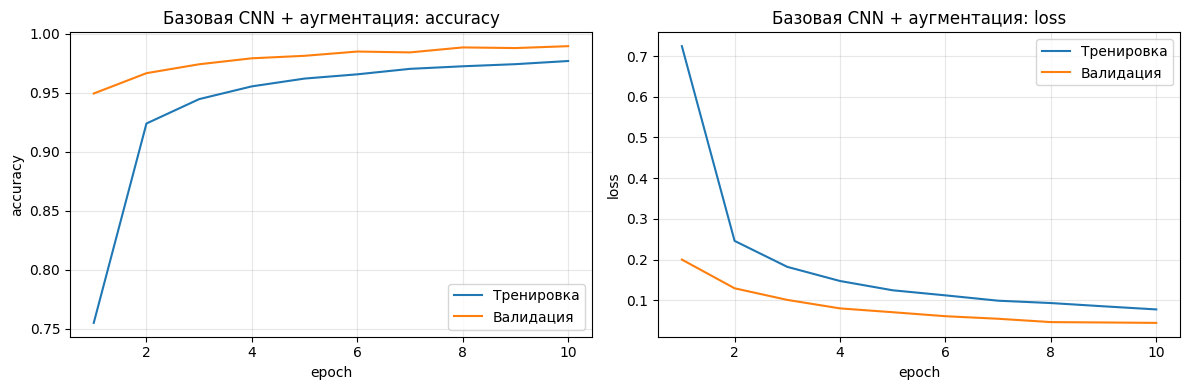

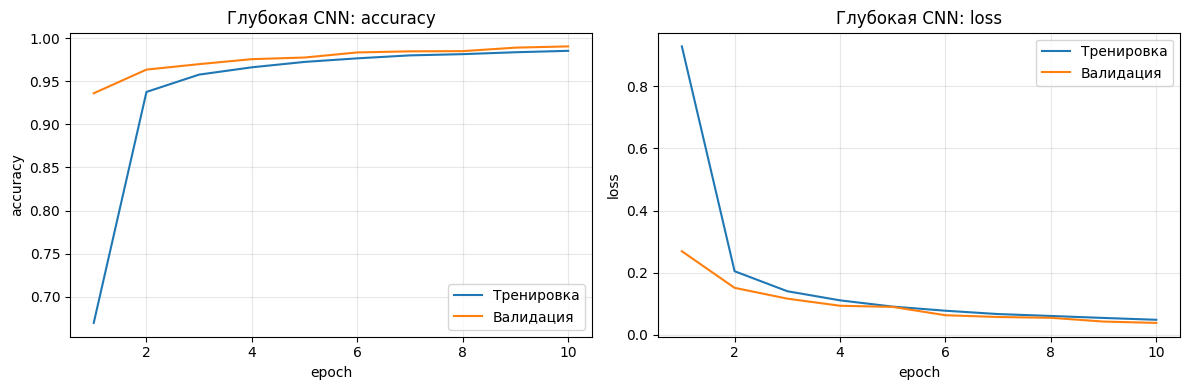

In [11]:
for name, _, _ in experiments:
    model_runs = [run for run in runs if run['name'] == name]
    train_accuracy = torch.tensor([run['train_accuracy'] for run in model_runs]).mean(dim=0)
    val_accuracy = torch.tensor([run['val_accuracy'] for run in model_runs]).mean(dim=0)
    train_loss = torch.tensor([run['train_loss'] for run in model_runs]).mean(dim=0)
    val_loss = torch.tensor([run['val_loss'] for run in model_runs]).mean(dim=0)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, epochs + 1), train_accuracy, label='Тренировка')
    plt.plot(range(1, epochs + 1), val_accuracy, label='Валидация')
    plt.title(name + ': accuracy')
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(range(1, epochs + 1), train_loss, label='Тренировка')
    plt.plot(range(1, epochs + 1), val_loss, label='Валидация')
    plt.title(name + ': loss')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


**СДВИГ ИЗОБРАЖЕНИЙ**

dx — вправо, dy — вниз. Отрицательные значения сдвигают в обратную сторону.
Вышедшие за границы пиксели обрезаются. Функция работает с одним изображением
(1, 28, 28) или целым batch (N, 1, 28, 28).


In [12]:
def shift_image(image, dx, dy):
    h, w = image.shape[-2:]
    shifted = torch.zeros_like(image)
    if abs(dx) >= w or abs(dy) >= h:
        return shifted

    x_start, x_end = max(0, dx), min(w, w + dx)
    y_start, y_end = max(0, dy), min(h, h + dy)
    source_x_start, source_x_end = max(0, -dx), min(w, w - dx)
    source_y_start, source_y_end = max(0, -dy), min(h, h - dy)

    shifted[..., y_start:y_end, x_start:x_end] = image[
        ..., source_y_start:source_y_end, source_x_start:source_x_end]
    return shifted


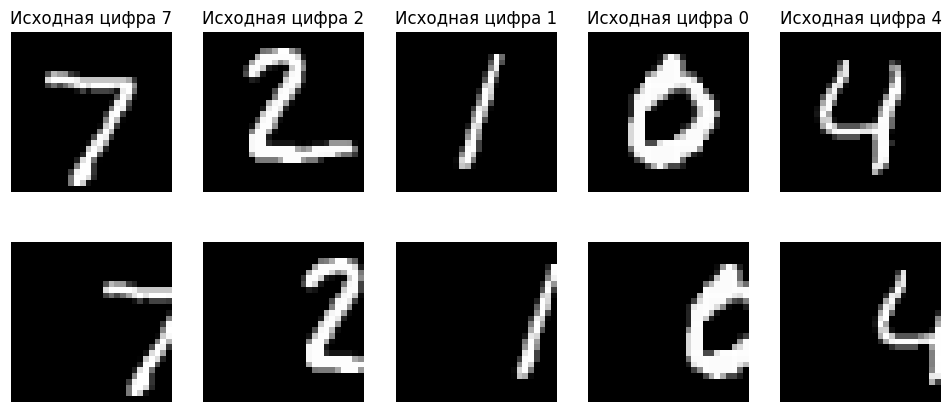

In [13]:
images, labels = next(iter(test_loader))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(images[i, 0], cmap='gray')
    axes[0, i].set_title(f'Исходная цифра {labels[i].item()}')
    axes[0, i].axis('off')
    axes[1, i].imshow(shift_image(images[i], 10, 0)[0], cmap='gray')
    axes[1, i].axis('off')

plt.show()


**ПРОВЕРКА НА TEST**

Сначала сдвигаем все цифры вправо на 0–14 пикселей, затем проверяем случайные
сдвиги по двум осям с пределом 0–10 пикселей. Генератор с одним seed даёт каждой
модели одинаковые случайные сдвиги. Модели и настройки по результатам test не выбираем.


In [14]:
for run in runs:
    model = run['model'].to(device)
    model.eval()
    right_accuracy, random_accuracy = [], []
    print(f"\n{run['name']}, seed={run['seed']}")

    with torch.no_grad():
        for dx in range(15):
            correct = 0
            for images, labels in test_loader:
                images = shift_image(images, dx, 0).to(device)
                labels = labels.to(device)
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()

            accuracy = correct / len(test_data)
            right_accuracy.append(accuracy)
            print(f'Сдвиг вправо на {dx} px: {accuracy:.4f}')

        generator = torch.Generator().manual_seed(2026)
        for limit in range(11):
            correct = 0
            for images, labels in test_loader:
                offsets = torch.randint(-limit, limit + 1, (len(images), 2), generator=generator)
                images = torch.stack([
                    shift_image(image, dx.item(), dy.item())
                    for image, (dx, dy) in zip(images, offsets)
                ]).to(device)
                labels = labels.to(device)
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()

            accuracy = correct / len(test_data)
            random_accuracy.append(accuracy)
            print(f'Случайный сдвиг до {limit} px: {accuracy:.4f}')

    run['right_accuracy'] = right_accuracy
    run['random_accuracy'] = random_accuracy
    model.cpu()



Базовая CNN, seed=111
Сдвиг вправо на 0 px: 0.9927
Сдвиг вправо на 1 px: 0.9899
Сдвиг вправо на 2 px: 0.9784
Сдвиг вправо на 3 px: 0.9391
Сдвиг вправо на 4 px: 0.8075
Сдвиг вправо на 5 px: 0.5995
Сдвиг вправо на 6 px: 0.4282
Сдвиг вправо на 7 px: 0.2995
Сдвиг вправо на 8 px: 0.2001
Сдвиг вправо на 9 px: 0.1471
Сдвиг вправо на 10 px: 0.1357
Сдвиг вправо на 11 px: 0.1449
Сдвиг вправо на 12 px: 0.1391
Сдвиг вправо на 13 px: 0.1168
Сдвиг вправо на 14 px: 0.1051
Случайный сдвиг до 0 px: 0.9927
Случайный сдвиг до 1 px: 0.9866
Случайный сдвиг до 2 px: 0.9578
Случайный сдвиг до 3 px: 0.8608
Случайный сдвиг до 4 px: 0.7228
Случайный сдвиг до 5 px: 0.5864
Случайный сдвиг до 6 px: 0.4645
Случайный сдвиг до 7 px: 0.3855
Случайный сдвиг до 8 px: 0.3183
Случайный сдвиг до 9 px: 0.2778
Случайный сдвиг до 10 px: 0.2392

Базовая CNN, seed=222
Сдвиг вправо на 0 px: 0.9930
Сдвиг вправо на 1 px: 0.9907
Сдвиг вправо на 2 px: 0.9770
Сдвиг вправо на 3 px: 0.9022
Сдвиг вправо на 4 px: 0.7158
Сдвиг вправо на 

**СРАВНЕНИЕ МОДЕЛЕЙ**

Линии — средняя accuracy, полупрозрачная область — +- одно стандартное отклонение
по seed. Красный цвет — базовая сеть, зелёный — базовая с аугментацией, синий — глубокая.


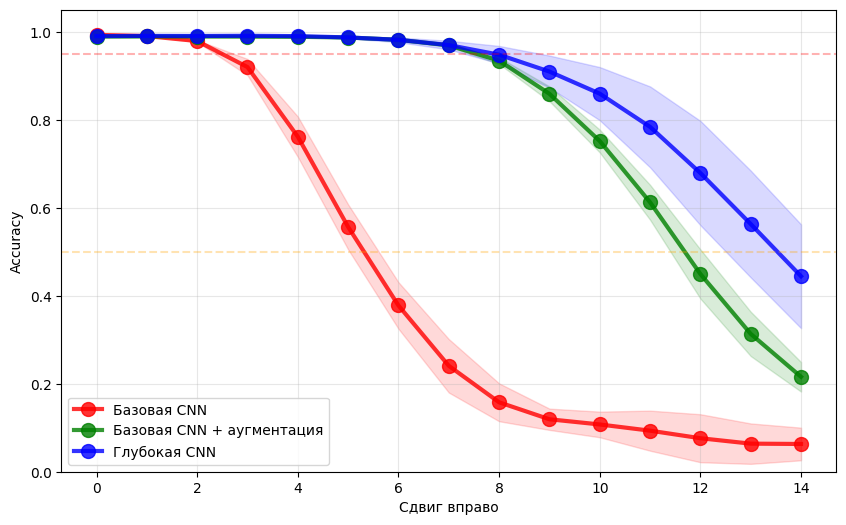

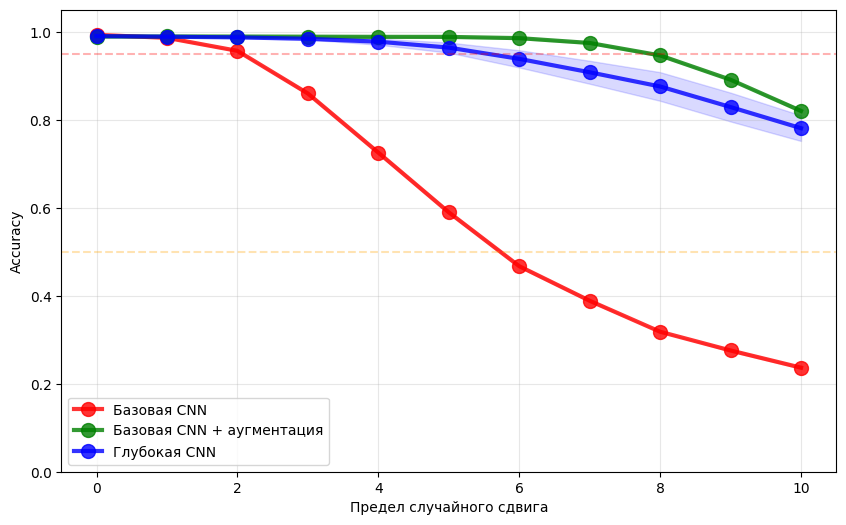

In [15]:
for key, xlabel, length in [
    ('right_accuracy', 'Сдвиг вправо', 15),
    ('random_accuracy', 'Предел случайного сдвига', 11)
]:
    plt.figure(figsize=(10, 6))

    for (name, _, _), color in zip(experiments, ['r', 'g', 'b']):
        scores = torch.tensor([run[key] for run in runs if run['name'] == name])
        mean = scores.mean(dim=0)
        std = scores.std(dim=0)
        plt.plot(range(length), mean, color + 'o-', linewidth=3,
                 markersize=10, label=name, alpha=0.8)
        plt.fill_between(range(length), mean - std, mean + std, color=color, alpha=0.15)

    plt.axhline(y=0.95, color='r', linestyle='--', alpha=0.3)
    plt.axhline(y=0.50, color='orange', linestyle='--', alpha=0.3)
    plt.xlabel(xlabel)
    plt.ylabel('Accuracy')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.ylim(0, 1.05)
    plt.show()


In [16]:
for name, _, _ in experiments:
    model_runs = [run for run in runs if run['name'] == name]
    print('\n' + name)
    for key, index, label in [
        ('right_accuracy', 0, 'Без сдвига'),
        ('right_accuracy', 7, 'Вправо 7 px'),
        ('right_accuracy', 14, 'Вправо 14 px'),
        ('random_accuracy', 10, 'Случайный до 10 px')
    ]:
        values = torch.tensor([run[key][index] for run in model_runs])
        print(f'{label}: {values.mean():.4f} ± {values.std():.4f}')



Базовая CNN
Без сдвига: 0.9929 ± 0.0002
Вправо 7 px: 0.2407 ± 0.0608
Вправо 14 px: 0.0631 ± 0.0371
Случайный до 10 px: 0.2365 ± 0.0023

Базовая CNN + аугментация
Без сдвига: 0.9890 ± 0.0010
Вправо 7 px: 0.9691 ± 0.0032
Вправо 14 px: 0.2157 ± 0.0336
Случайный до 10 px: 0.8200 ± 0.0038

Глубокая CNN
Без сдвига: 0.9900 ± 0.0005
Вправо 7 px: 0.9697 ± 0.0098
Вправо 14 px: 0.4442 ± 0.1180
Случайный до 10 px: 0.7807 ± 0.0291


**ВЫВОДЫ**

Как видно, выбор архитектуры существенно важен в данной задаче.